# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Lioneil Diyoel Trystan Tikupadang | 5054251037 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [192]:
# Import library yang dibutuhkan:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.precision", 4)

In [193]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

data_path = "Mall_Customers.csv"
df = pd.read_csv(data_path)

print("5 baris pertama:")
display(df.head())

print("\nJumlah baris dan kolom:", df.shape)

print("\nTipe data setiap kolom:")
print(df.dtypes)

print("\nStatistik deskriptif:\n")
display(df.describe(include="all").transpose())

print("\nJumlah missing value per kolom:")
print(df.isna().sum())

print("\nJumlah baris duplikat:", df.duplicated().sum())

5 baris pertama:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Jumlah baris dan kolom: (200, 5)

Tipe data setiap kolom:
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik deskriptif:



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.8792,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.2647,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.8235,1.0,34.75,50.0,73.0,99.0



Jumlah missing value per kolom:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0


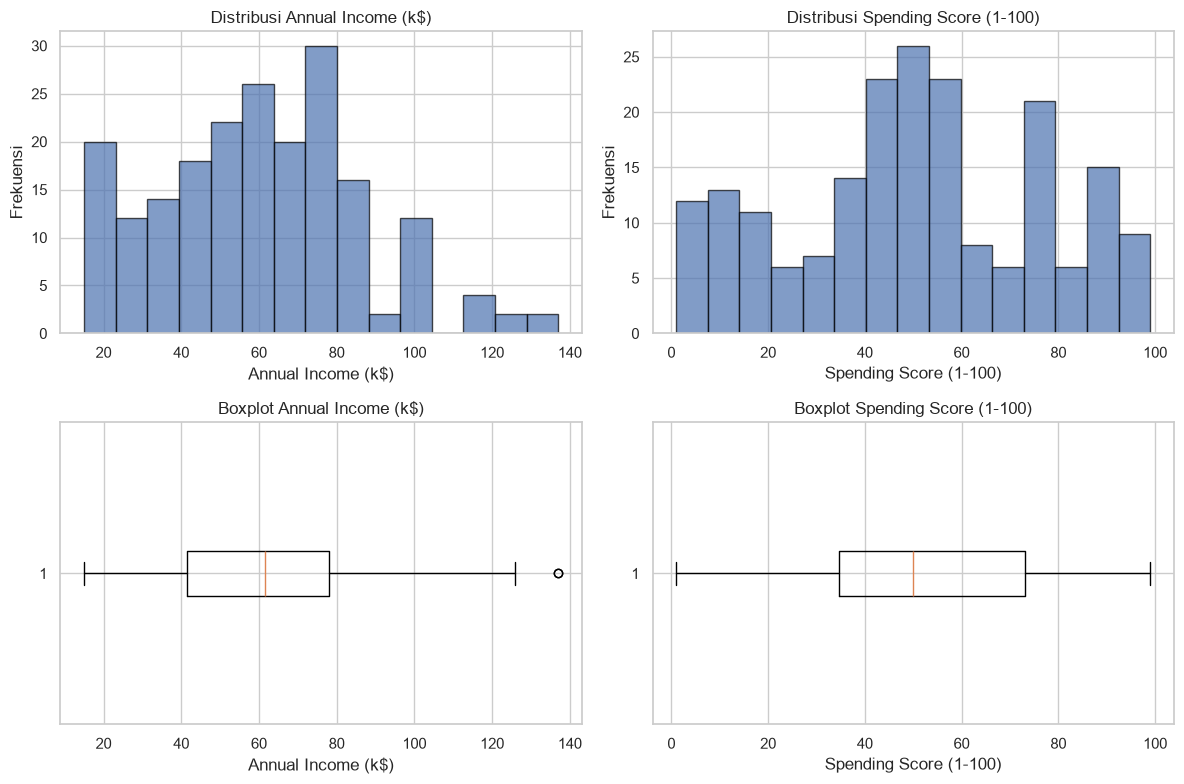

In [194]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.

features_to_plot = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for i, feature in enumerate(features_to_plot):
    axes[0, i].hist(df[feature], bins=15, alpha=0.7, edgecolor='black')
    axes[0, i].set_title(f'Distribusi {feature}')
    axes[0, i].set_xlabel(feature)
    axes[0, i].set_ylabel('Frekuensi')

    axes[1, i].boxplot(df[feature], vert=False)
    axes[1, i].set_title(f'Boxplot {feature}')
    axes[1, i].set_xlabel(feature)

plt.tight_layout()
plt.show()

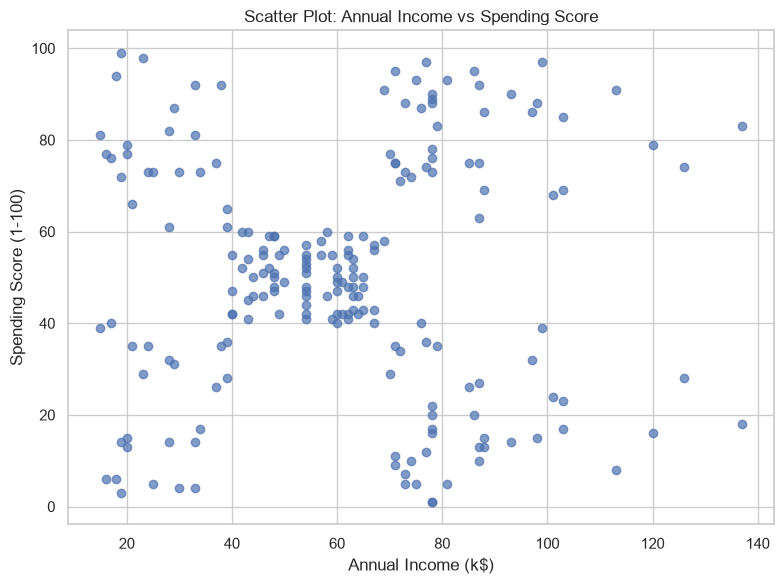

In [195]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 6))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], alpha=0.7)
plt.title("Scatter Plot: Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.tight_layout()
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

## Jawaban:

- Tidak ditemukan missing value pada kelima kolom dan tidak ada baris duplikat.
- Rentang fitur: `Annual Income (k$)` berada pada rentang 15–137 dengan median 61,5. `Spending Score (1-100)` berada pada rentang 1–99 dengan median 50.
- Scatter plot memperlihatkan pola beberapa kelompok yang cukup terlihat, terutama pelanggan berpendapatan rendah dengan spending score tinggi/rendah, pelanggan berpendapatan menengah dengan spending score menengah, serta pelanggan berpendapatan tinggi dengan spending score tinggi/rendah. Batas antarkelompok tidak seluruhnya terpisah sehingga clustering tetap diperlukan.

# 2. Preprocessing

In [196]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan. (TIDAK ADA)
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

features = ["Annual Income (k$)", "Spending Score (1-100)"]

X = df[features].copy()
print("Data untuk clustering:")
display(X.head())
print("Ukuran X:", X.shape)


Data untuk clustering:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


Ukuran X: (200, 2)


In [197]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=features, index=X.index)

print("5 baris pertama X_scaled:")
display(X_scaled.head())

print("Statistik deskriptif X_scaled:")
display(X_scaled.describe())

5 baris pertama X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.7390,-0.4348
1,-1.7390,1.1957
2,-1.7008,-1.7159
3,-1.7008,1.0404
4,-1.6627,-0.3960


Statistik deskriptif X_scaled:


,Annual Income (k$),Spending Score (1-100)
count,2.0000e+02,2.0000e+02
mean,-2.1316e-16,-1.4655e-16
std,1.0025e+00,1.0025e+00
min,-1.7390e+00,-1.9100e+00
25%,-7.2751e-01,-5.9979e-01
50%,3.5879e-02,-7.7643e-03
75%,6.6567e-01,8.8513e-01
max,2.9177e+00,1.8945e+00


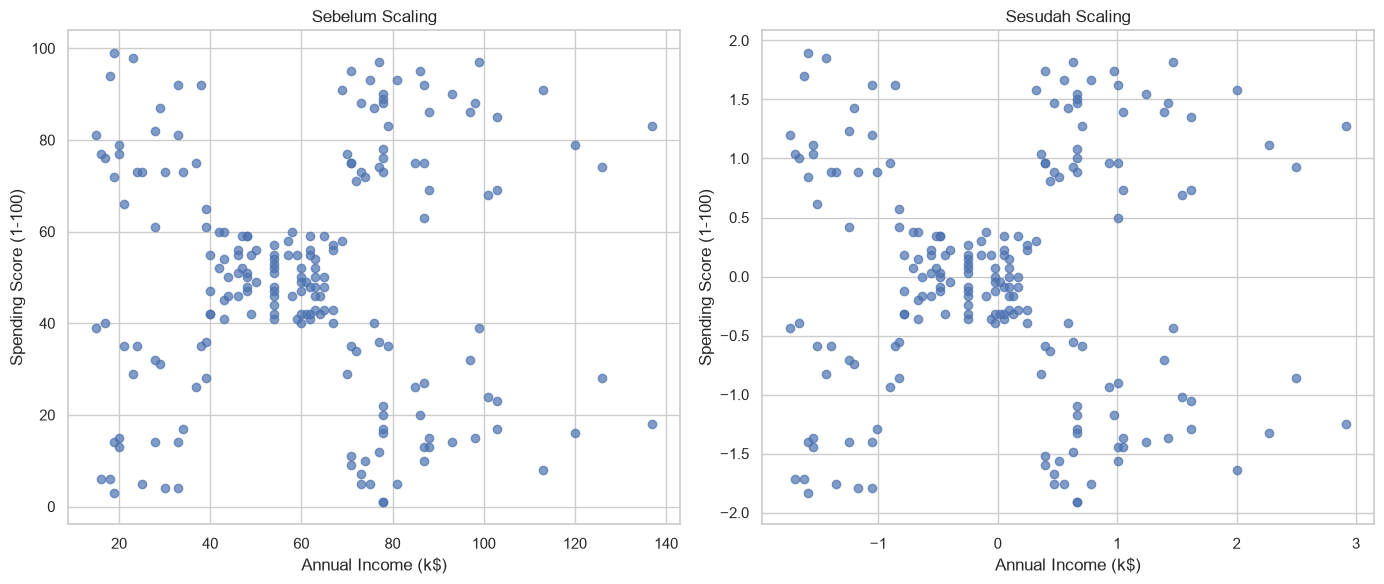

In [198]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X[features[0]], X[features[1]], alpha=0.7)
axes[0].set_title("Sebelum Scaling")
axes[0].set_xlabel(features[0])
axes[0].set_ylabel(features[1])

axes[1].scatter(X_scaled[features[0]], X_scaled[features[1]], alpha=0.7)
axes[1].set_title("Sesudah Scaling")
axes[1].set_xlabel(features[0])
axes[1].set_ylabel(features[1])

plt.tight_layout()
plt.show()

#### **Mengapa Scaling Penting?**
Scaling mengubah kedua fitur agar memiliki rata-rata sekitar 0 dan standar deviasi sekitar 1. Hal ini diperlukan untuk algoritma berbasis jarak seperti DBSCAN dan BIRCH, serta mencegah fitur dengan rentang/nilai numerik lebih besar mendominasi proses clustering.

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

`Annual Income (k$)` menggambarkan kemampuan ekonomi pelanggan, sedangkan `Spending Score (1-100)` menggambarkan kecenderungan/pola belanja. Kombinasi keduanya dapat membantu membedakan segmen pelanggan berdasarkan tingkat pendapatan dan pengeluaran, serta mudah divisualisasikan dalam scatter plot dua dimensi.

`CustomerID` tidak digunakan karena hanya nomor identitas/penanda unik pelanggan dan tidak merepresentasikan karakteristik atau perilaku pelanggan.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [199]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan_initial = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan_initial = dbscan_initial.fit_predict(X_scaled)
labels_dbscan = labels_dbscan_initial.copy()

print("Parameter DBSCAN awal: eps=0.3, min_samples=5")
print("Label cluster awal:", np.unique(labels_dbscan_initial))

Parameter DBSCAN awal: eps=0.3, min_samples=5
Label cluster awal: [-1  0  1  2  3  4  5  6]


In [200]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

jumlah_label_dbscan_awal = pd.Series(labels_dbscan_initial).value_counts().sort_index()
print("Jumlah anggota setiap label:")
display(jumlah_label_dbscan_awal.rename("Jumlah Anggota").to_frame())

jumlah_cluster_awal = len(set(labels_dbscan_initial) - {-1})  
jumlah_noise_awal = int(np.sum(labels_dbscan_initial == -1))

print(f"Jumlah cluster (tidak termasuk noise): {jumlah_cluster_awal}")
print(f"Jumlah titik noise (label -1): {jumlah_noise_awal}")

Jumlah anggota setiap label:


,Jumlah Anggota
-1,35
0,12
1,5
2,7
3,88
4,30
5,14
6,9


Jumlah cluster (tidak termasuk noise): 7
Jumlah titik noise (label -1): 35


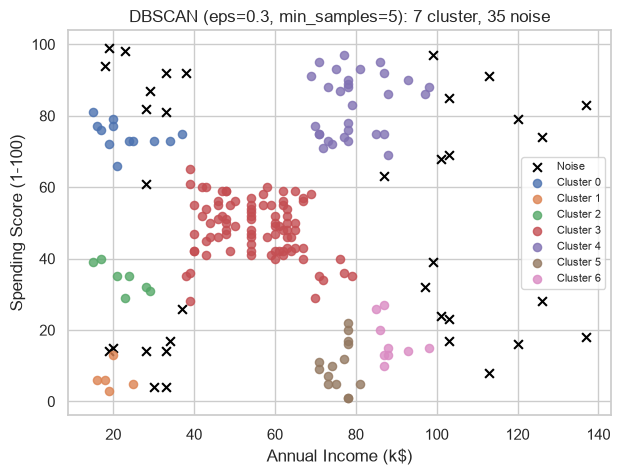

In [201]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

def plot_cluster(ax, data, labels, title, noise_label=-1):
    for lab in np.unique(labels):
        mask = labels == lab
        if lab == noise_label:
            ax.scatter(data.iloc[mask, 0], data.iloc[mask, 1], c='black', marker='x', s=40, label='Noise')
        else:
            ax.scatter(data.iloc[mask, 0], data.iloc[mask, 1], s=35, alpha=0.8, label=f'Cluster {lab}')
    ax.set_title(title)
    ax.set_xlabel('Annual Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(7, 5))
plot_cluster(ax, X, labels_dbscan, f'DBSCAN (eps=0.3, min_samples=5): {jumlah_cluster_awal} cluster, {jumlah_noise_awal} noise')
plt.show()

In [202]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

hasil_dbscan = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k = len(set(lab)) - (1 if -1 in lab else 0)
        noise = int((lab == -1).sum())
        mask = lab != -1

        if k >= 2 and mask.sum() > k:
            sil = silhouette_score(X_scaled[mask], lab[mask])
        else:
            sil = np.nan
        hasil_dbscan.append({'eps': eps, 'min_samples': ms, 'jumlah_cluster': k,
                             'jumlah_noise': noise, 'persen_noise': round(100 * noise / len(lab), 1),
                             'silhouette (non-noise)': round(sil, 4) if not np.isnan(sil) else np.nan})

df_dbscan = pd.DataFrame(hasil_dbscan)

print("Ringkasan eksperimen DBSCAN:")
display(df_dbscan)

dbscan_best_params = {"eps": 0.4, "min_samples": 8}
dbscan_best = DBSCAN(**dbscan_best_params)
labels_dbscan = dbscan_best.fit_predict(X_scaled)
print(f"\nParameter DBSCAN terbaik:", dbscan_best_params)
print("Jumlah cluster:", len(set(labels_dbscan) - {-1}))
print("Jumlah noise:", int(np.sum(labels_dbscan == -1)))

Ringkasan eksperimen DBSCAN:


,eps,min_samples,jumlah_cluster,jumlah_noise,persen_noise,silhouette (non-noise)
0,0.2,3,13,44,22.0,0.4697
1,0.2,5,7,77,38.5,0.5856
2,0.2,8,2,116,58.0,0.6027
3,0.2,10,1,129,64.5,NaN
4,0.3,3,9,14,7.0,0.4720
5,0.3,5,7,35,17.5,0.5243
6,0.3,8,5,72,36.0,0.5926
7,0.3,10,4,88,44.0,0.6073
8,0.4,3,4,10,5.0,0.3954
9,0.4,5,4,15,7.5,0.4781



Parameter DBSCAN terbaik: {'eps': 0.4, 'min_samples': 8}
Jumlah cluster: 5
Jumlah noise: 25


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**

- **Pengaruh `eps` terhadap jumlah cluster dan noise:** pada `min_samples=5`, jumlah noise terus turun dari 77 (eps=0,2) menjadi 35 (0,3), 15 (0,4), 8 (0,5), dan 5 (0,6). Jumlah cluster mula-mula tinggi (7 cluster pada eps 0,2 dan 0,3) karena kelompok terpecah menjadi bagian-bagian kecil, lalu turun menjadi 4 (eps 0,4), 2 (eps 0,5), dan akhirnya 1 cluster (eps 0,6) karena kelompok-kelompok yang berdekatan saling tersambung. Jadi, `eps` yang lebih besar memperluas lingkungan tetangga sehingga titik lebih mudah terhubung, cluster dapat bergabung, dan noise berkurang.
- **Pengaruh `min_samples`:** pada `eps` yang sama, `min_samples` yang lebih besar mengharuskan kepadatan lebih tinggi sehingga noise bertambah. Contoh pada eps=0,3: `min_samples` 3, 5, 8, 10 menghasilkan noise 14, 35, 72, 88 dan cluster 9, 7, 5, 4. Kelompok kecil yang tidak cukup padat berubah menjadi noise.
- **Kombinasi bermasalah:** satu cluster besar muncul pada eps 0,6 pada semua `min_samples` yang dicoba (1 cluster dengan 0 sampai 10 noise), dan juga pada eps=0,2 dengan `min_samples=10` (1 cluster dengan 129 noise). Noise berlebihan terjadi pada eps=0,2 dengan `min_samples` 5, 8, 10 (38,5%, 58%, 64,5% data) serta eps=0,3 dengan `min_samples` 8 dan 10 (36% dan 44%). Silhouette tertinggi (0,6073 pada eps=0,3, `min_samples=10`) memiliki 44% data yang merupakan noise, didapatkan silhouette saja tidak cukup untuk memilih parameter.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [203]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch_initial = Birch(threshold=0.5, n_clusters=5)
labels_birch_initial = birch_initial.fit_predict(X_scaled)
labels_birch = labels_birch_initial.copy()

print("Parameter Birch awal: threshold=0.5, n_clusters=5")
print("Jumlah cluster awal:", len(np.unique(labels_birch_initial)))

Parameter Birch awal: threshold=0.5, n_clusters=5
Jumlah cluster awal: 5


In [204]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

jumlah_label_birch_awal = pd.Series(labels_birch_initial).value_counts().sort_index()
print("Jumlah anggota setiap cluster BIRCH:")
display(jumlah_label_birch_awal.rename("Jumlah Anggota").to_frame())
print("Jumlah cluster BIRCH:", len(np.unique(labels_birch_initial)))

Jumlah anggota setiap cluster BIRCH:


,Jumlah Anggota
0,36
1,109
2,8
3,25
4,22


Jumlah cluster BIRCH: 5


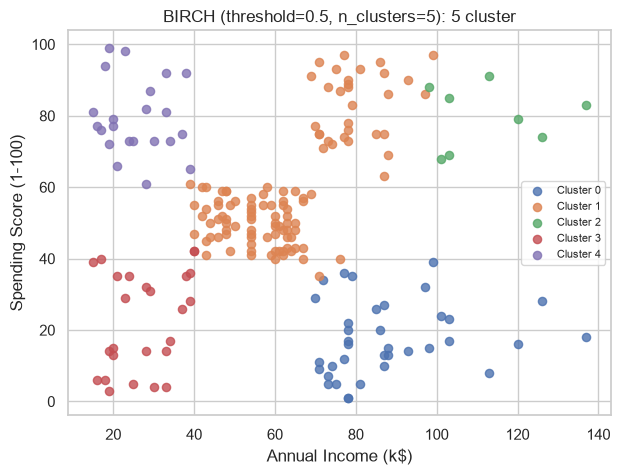

In [205]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

fig, ax = plt.subplots(figsize=(7, 5))
plot_cluster(ax, X, labels_birch,
             f'BIRCH (threshold=0.5, n_clusters=5): {len(np.unique(labels_birch))} cluster', noise_label=None)
plt.show()

In [206]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

hasil_birch = []
for threshold in [0.3, 0.5, 0.7, 1.0]:
    model = Birch(threshold=threshold, n_clusters=5).fit(X_scaled)
    lab5 = model.labels_
    birch_n = Birch(threshold=threshold, n_clusters=None).fit(X_scaled)
    labn = birch_n.labels_
    k5, kn = len(np.unique(lab5)), len(np.unique(labn))
    hasil_birch.append({'threshold': threshold,
                        'jumlah_subcluster': len(model.subcluster_centers_),
                        'jumlah_cluster (n_clusters=5)': k5,
                        'silhouette (n_clusters=5)': round(silhouette_score(X_scaled, lab5), 4) if k5 > 1 else np.nan,
                        'jumlah_cluster (n_clusters=None)': kn,
                        'silhouette (n_clusters=None)': round(silhouette_score(X_scaled, labn), 4) if kn > 1 else np.nan})

df_birch = pd.DataFrame(hasil_birch)
print("Ringkasan eksperimen BIRCH:")
display(df_birch)

birch_best_params = {"threshold": 0.3, "n_clusters": 5}
birch_best = Birch(**birch_best_params)
labels_birch = birch_best.fit_predict(X_scaled)
print(f"\nParameter BIRCH terbaik:", birch_best_params)
print("Jumlah cluster:", len(np.unique(labels_birch)))

Ringkasan eksperimen BIRCH:


,threshold,jumlah_subcluster,jumlah_cluster (n_clusters=5),silhouette (n_clusters=5),jumlah_cluster (n_clusters=None),silhouette (n_clusters=None)
0,0.3,23,5,0.4781,23,0.4143
1,0.5,10,5,0.4145,10,0.4774
2,0.7,6,5,0.4207,6,0.4861
3,1.0,4,4,0.3886,4,0.3886



Parameter BIRCH terbaik: {'threshold': 0.3, 'n_clusters': 5}
Jumlah cluster: 5


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**

- **Pengaruh `threshold` yang diperbesar:** Threshold yang lebih besar membuat titik dengan jarak lebih besar masih dapat digabungkan ke subcluster yang sama, sehingga jumlah subcluster internal cenderung berkurang. Dengan `n_clusters=5`, jumlah cluster akhir tetap 5 selama subcluster masih cukup banyak, tetapi pada threshold 1,0 hanya terbentuk 4 cluster karena karena jumlah subcluster internal yang tersedia tidak cukup. Silhouette pada `n_clusters=5` tidak berubah monoton (0,478; 0,414; 0,421; 0,389).
- **Perbdaan dengan DBSCAN:**BIRCH tidak memberi label noise secara eksplisit. Titik yang jauh dari kelompok utama tetap akan dimasukkan ke salah satu cluster akhir, sedangkan DBSCAN dapat memberi label `-1` pada titik yang tidak memenuhi kepadatan minimum.
- **Efek `n_clusters`:** Hasilnya berubah ketika `n_clusters`. Dengan `n_clusters=None`, subcluster langsung menjadi cluster akhir (misalnya 10 cluster pada threshold 0,5), sedangkan `n_clusters=5` hasilnya 5 cluster dan 4 cluster pada threshold 1.0 . Silhouette ikut berubah, misalnya pada threshold 0,3 turun dari 0,478 (n_clusters=5) menjadi 0,414 (None), sedangkan pada threshold 0,5 naik dari 0,414 menjadi 0,477. Silhouette yang lebih tinggi pada `n_clusters=None` juga tidak berarti hasilnya lebih baik, karena clusternya lebih banyak dan lebih sulit diinterpretasi.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [207]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm_model = GaussianMixture(n_components=5, covariance_type='full', random_state=42)

gmm_model.fit(X_scaled)
labels_gmm = gmm_model.predict(X_scaled)

print("Parameter GMM: n_components=5, covariance_type='full', random_state=42")
print("Jumlah cluster GMM:", len(np.unique(labels_gmm)))

Parameter GMM: n_components=5, covariance_type='full', random_state=42
Jumlah cluster GMM: 5


In [208]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

jumlah_label_gmm = pd.Series(labels_gmm).value_counts().sort_index()
print("Jumlah anggota setiap cluster GMM:")
display(jumlah_label_gmm.rename("Jumlah Anggota").to_frame())

proba = gmm_model.predict_proba(X_scaled)
df_proba = pd.DataFrame(proba, columns=[f'P(komp {i})' for i in range(proba.shape[1])])
df_proba['label_gmm'] = labels_gmm
df_proba['prob_maks'] = proba.max(axis=1).round(4)

print('\nBeberapa baris probabilitas keanggotaan:')
display(df_proba.head(10))

uncertain = df_proba[df_proba['prob_maks'] < 0.8].copy()
uncertain[['Annual Income (k$)', 'Spending Score (1-100)']] = X.loc[uncertain.index, ['Annual Income (k$)', 'Spending Score (1-100)']]

print(f'\nJumlah titik dengan probabilitas maksimum < 0.8: {len(uncertain)}')
display(uncertain[['Annual Income (k$)', 'Spending Score (1-100)', 'label_gmm', 'prob_maks']].head(10))

Jumlah anggota setiap cluster GMM:


,Jumlah Anggota
0,84
1,39
2,21
3,33
4,23



Beberapa baris probabilitas keanggotaan:


,P(komp 0),P(komp 1),P(komp 2),P(komp 3),P(komp 4),label_gmm,prob_maks
0,1.5769e-05,1.8801e-08,9.5203e-04,5.2001e-08,9.9903e-01,4,0.9990
1,1.6278e-05,1.8960e-04,9.9979e-01,4.2101e-23,3.9415e-06,2,0.9998
2,2.2134e-19,9.5262e-19,1.2255e-12,1.8622e-04,9.9981e-01,4,0.9998
3,1.0544e-04,1.8009e-04,9.9969e-01,3.7939e-21,2.0723e-05,2,0.9997
4,6.4730e-05,3.8427e-08,1.5567e-03,4.7572e-08,9.9838e-01,4,0.9984
5,1.8333e-04,1.8991e-04,9.9959e-01,1.4358e-20,3.5098e-05,2,0.9996
6,9.2137e-19,1.2895e-18,1.4084e-12,2.5484e-04,9.9975e-01,4,0.9997
7,1.2966e-08,3.2331e-04,9.9968e-01,8.5929e-29,8.0293e-08,2,0.9997
8,4.0615e-20,1.3439e-19,1.9066e-13,4.1709e-04,9.9958e-01,4,0.9996
9,1.2001e-03,2.0400e-04,9.9837e-01,1.6277e-18,2.2267e-04,2,0.9984



Jumlah titik dengan probabilitas maksimum < 0.8: 6


,Annual Income (k$),Spending Score (1-100),label_gmm,prob_maks
27,28,61,2,0.6746
48,40,42,0,0.6114
49,40,42,0,0.6114
55,43,41,0,0.7959
124,70,29,3,0.5029
160,79,35,0,0.7721


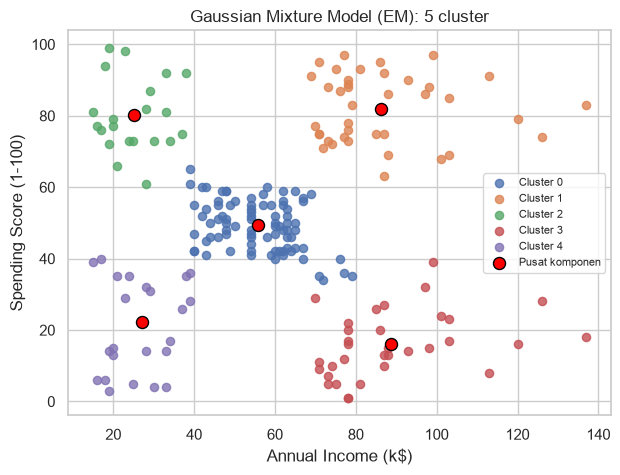

In [209]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

fig, ax = plt.subplots(figsize=(7, 5))
plot_cluster(ax, X, labels_gmm, 'Gaussian Mixture Model (EM): 5 cluster', noise_label=None)
means = scaler.inverse_transform(gmm_model.means_)
ax.scatter(means[:, 0], means[:, 1], c='red', s=75, edgecolor='black', label='Pusat komponen')
ax.legend(fontsize=8)
plt.show()

In [210]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

hasil_gmm = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    lab = g.predict(X_scaled)
    hasil_gmm.append({'n_components': k,
                      'silhouette': round(silhouette_score(X_scaled, lab), 4),
                      'BIC': round(g.bic(X_scaled), 2)})

df_gmm = pd.DataFrame(hasil_gmm)
display(df_gmm)
print('Silhouette tertinggi pada n_components =', df_gmm.loc[df_gmm['silhouette'].idxmax(), 'n_components'])
print('BIC terendah pada n_components =', df_gmm.loc[df_gmm['BIC'].idxmin(), 'n_components'])

,n_components,silhouette,BIC
0,2,0.3791,1153.90
1,3,0.4302,1151.72
2,4,0.4134,1103.79
3,5,0.5537,1058.65
4,6,0.5170,1074.68
5,7,0.5091,1087.33
6,8,0.4302,1102.37


Silhouette tertinggi pada n_components = 5
BIC terendah pada n_components = 5


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban**:

- **Arti probabilitas keanggotaan:** `predict_proba` menghasilkan probabilitas untuk setiap pelanggan masuk ke masing-masing cluster/komponen Gaussian. Nilai probabilitas seluruh komponen untuk satu titik berjumlah 1. Label akhir diambil dari komponen dengan probabilitas terbesar. Pada hasil, sebagian besar titik memiliki probabilitas maksimum di atas 0,99, tetapi terdapat 6 titik yang memiliki probabilitas maksimum di bawah 0,8. Titik 124 paling tidak pasti, yaitu 0,503 untuk komponen 3, karena berada di perbatasan dua cluster.
- **`n_components` diubah:** Jumlah komponen mengubah banyaknya distribusi Gaussian yang digunakan untuk memodelkan data. Pada percobaan ini, Silhouette Score tertinggi diperoleh pada 5 komponen (sekitar 0,5537), dan nilai BIC terendah juga diperoleh pada 5 komponen (sekitar 1058,65). Menambah komponen setelah 5 tidak memperbaiki kedua hasil tersebut.
- **Mengapa jumlah cluster harus ditentukan di awal:** GMM perlu mengetahui jumlah komponen Gaussian yang akan diestimasi sebelum parameter model (bobot, mean, dan kovarians) dipelajari dengan EM. Karena itu, beberapa kandidat `n_components` perlu dibandingkan.
- **Silhouette tertinggi sama dengan BIC terendah?** Ya. Keduanya menunjuk n_components = 5.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [211]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluasi_clustering(X_data, labels, noise_label=-1):
    X_arr = np.asarray(X_data)
    labels = np.asarray(labels)
    mask = labels != noise_label
    X_eval, lab_eval = X_arr[mask], labels[mask]
    n_cluster = len(np.unique(lab_eval))
    hasil = {'jumlah_cluster': n_cluster,
             'jumlah_noise': int((~mask).sum()),
             'silhouette': np.nan, 'davies_bouldin': np.nan, 'calinski_harabasz': np.nan}
    if n_cluster >= 2 and n_cluster < len(lab_eval):
        hasil['silhouette'] = silhouette_score(X_eval, lab_eval)
        hasil['davies_bouldin'] = davies_bouldin_score(X_eval, lab_eval)
        hasil['calinski_harabasz'] = calinski_harabasz_score(X_eval, lab_eval)
    return hasil

In [212]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# DBSCAN: silhouette tertinggi dengan syarat noise <= 15% data
kandidat_db = df_dbscan[(df_dbscan['jumlah_cluster'] >= 2) & (df_dbscan['persen_noise'] <= 15)]
best_db = kandidat_db.loc[kandidat_db['silhouette (non-noise)'].idxmax()]
eps_best, ms_best = best_db['eps'], int(best_db['min_samples'])

# BIRCH: silhouette tertinggi dengan n_clusters=5
best_bi = df_birch.loc[df_birch['silhouette (n_clusters=5)'].idxmax()]
th_best = best_bi['threshold']

# GMM: n_components dengan BIC terendah
k_best = int(df_gmm.loc[df_gmm['BIC'].idxmin(), 'n_components'])

print(f'DBSCAN terbaik : eps={eps_best}, min_samples={ms_best}')
print(f'BIRCH terbaik  : threshold={th_best}, n_clusters=5')
print(f'GMM terbaik    : n_components={k_best}, covariance_type=full')

best_labels_dbscan = DBSCAN(eps=eps_best, min_samples=ms_best).fit_predict(X_scaled)
best_labels_birch = Birch(threshold=th_best, n_clusters=5).fit_predict(X_scaled)
best_labels_gmm = GaussianMixture(n_components=k_best, covariance_type='full', random_state=42).fit(X_scaled).predict(X_scaled)

rows = []
for nama, lab in [('DBSCAN', best_labels_dbscan), ('BIRCH', best_labels_birch), ('GMM (EM)', best_labels_gmm)]:
    r = evaluasi_clustering(X_scaled, lab)
    r['jumlah_noise'] = r['jumlah_noise'] if nama == 'DBSCAN' else 'N/A'
    rows.append({'model': nama, **r})

df_eval = pd.DataFrame(rows).round(4)
display(df_eval)

DBSCAN terbaik : eps=0.4, min_samples=8
BIRCH terbaik  : threshold=0.3, n_clusters=5
GMM terbaik    : n_components=5, covariance_type=full


,model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,5,25,0.5490,0.5015,222.0651
1,BIRCH,5,N/A,0.4781,0.6477,144.0135
2,GMM (EM),5,N/A,0.5537,0.5760,244.9402


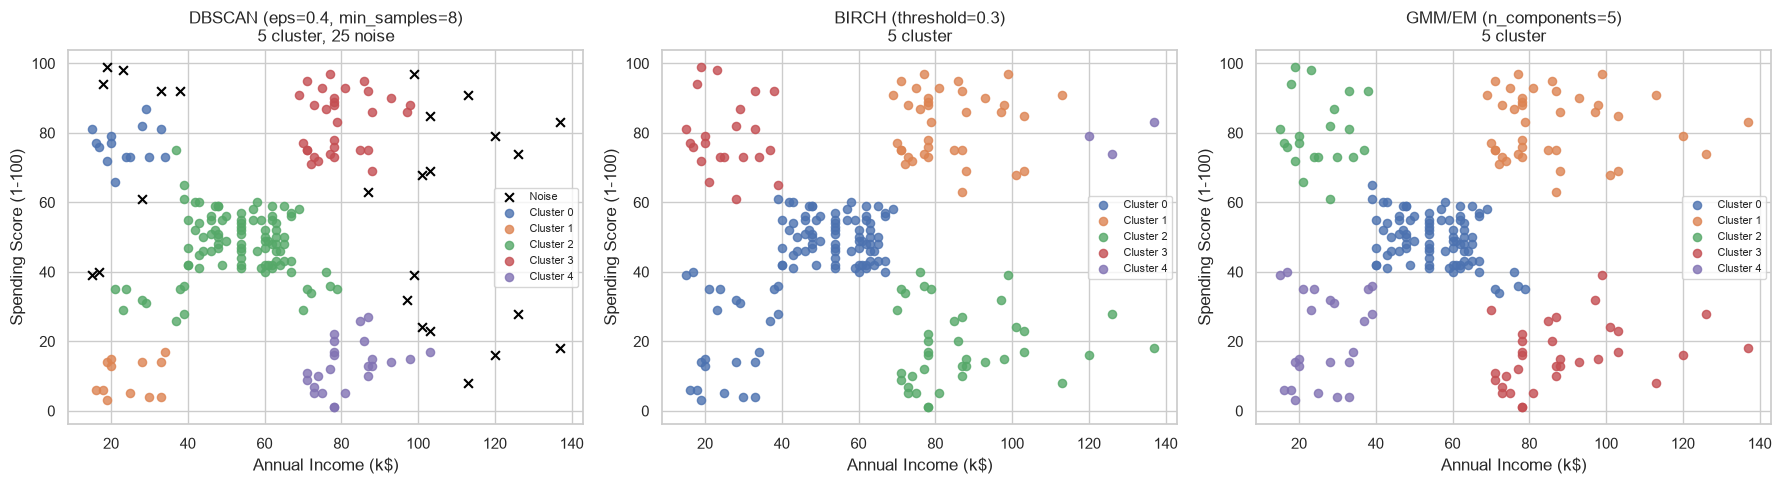

In [213]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
n_cl_db = len(set(best_labels_dbscan)) - (1 if -1 in best_labels_dbscan else 0)
n_no_db = int((best_labels_dbscan == -1).sum())
plot_cluster(axes[0], X, best_labels_dbscan,
             f'DBSCAN (eps={eps_best}, min_samples={ms_best})\n{n_cl_db} cluster, {n_no_db} noise')
plot_cluster(axes[1], X, best_labels_birch,
             f'BIRCH (threshold={th_best})\n{len(np.unique(best_labels_birch))} cluster', noise_label=None)
plot_cluster(axes[2], X, best_labels_gmm,
             f'GMM/EM (n_components={k_best})\n{len(np.unique(best_labels_gmm))} cluster', noise_label=None)
plt.tight_layout()
plt.show()

In [216]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

def profil_cluster(labels):
    tmp = X.copy()
    tmp['cluster'] = labels
    prof = tmp.groupby('cluster').agg(
        jumlah=('cluster', 'size'),
        median_income=(features[0], 'median'),
        mean_income=(features[0], 'mean'),
        median_spending=(features[1], 'median'),
        mean_spending=(features[1], 'mean')
    ).round(2)
    return prof

for nama, lab in [('DBSCAN', best_labels_dbscan), ('BIRCH', best_labels_birch), ('GMM (EM)', best_labels_gmm)]:
    prof = profil_cluster(lab)
    print(f'- Profil cluster {nama}')
    if nama == 'DBSCAN':
        print('Cluster (non-noise):')
        display(prof[prof.index != -1])
        print('Noise (label -1), dianalisis terpisah:')
        display(prof[prof.index == -1])
    else:
        display(prof)

- Profil cluster DBSCAN
Cluster (non-noise):


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,14,22.5,23.64,76.5,76.43
1,12,22.5,24.58,9.5,9.58
2,95,54.0,53.25,48.0,47.77
3,30,78.0,79.53,86.0,83.13
4,24,78.0,81.88,13.0,12.96


Noise (label -1), dianalisis terpisah:


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
-1,25,101.0,83.04,68.0,60.48


- Profil cluster BIRCH


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,101,50.0,48.17,47.0,43.40
1,36,78.0,83.11,85.5,82.42
2,38,80.0,87.00,16.5,18.63
3,22,24.5,25.73,77.0,79.36
4,3,126.0,127.67,79.0,78.67


- Profil cluster GMM (EM)


,jumlah,median_income,mean_income,median_spending,mean_spending
cluster,,,,,
0,84,55.5,55.64,49.5,49.37
1,39,79.0,86.54,83.0,82.13
2,21,24.0,25.10,77.0,80.05
3,33,86.0,88.82,15.0,16.00
4,23,25.0,26.30,17.0,20.91


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Dapat ditentukan melalui `n_clusters`; jika `None`, mengikuti subcluster hasil threshold | Ya, melalui `n_components` |
| Dapat memberi label noise secara eksplisit? | Ya, label `-1` | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk arbitrer berbasis keterhubungan kepadatan | Kelompok ringkasan subcluster; cocok untuk struktur yang relatif kompak | Bentuk Gaussian; dengan kovarians penuh dapat memodelkan kelompok elips |
| Kelebihan | Tidak perlu jumlah cluster awal dan dapat mendeteksi noise | Efisien melalui ringkasan CF Tree dan jumlah cluster akhir dapat diarahkan | Keanggotaan probabilistik dan model dapat dibandingkan dengan BIC |
| Kekurangan | Sensitif terhadap parameter dan kepadatan yang berbeda; data dapat banyak menjadi noise | Tidak menandai noise dan hasil dipengaruhi threshold | Jumlah komponen perlu ditentukan/dibandingkan dan asumsi Gaussian belum tentu cocok untuk semua bentuk data |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban:**

1. **Mengapa fitur perlu di-scaling?**
   DBSCAN, BIRCH, dan GMM sama-sama sensitif terhadap skala fitur. DBSCAN dan BIRCH mengukur kedekatan titik dengan jarak Euclidean, sedangkan GMM memakai varians dan kovarians. Jika satu fitur berskala jauh lebih besar, fitur itu akan lebih menentukan hasil clustering. Pada dataset ini, kedua fitur sebenarnya sudah berskala mirip (rentang 122 dan 98, standar deviasi 26,26 dan 25,82), sehingga bentuk sebaran sebelum dan sesudah scaling hampir sama. Meski begitu, `StandardScaler` tetap digunakan karena membuat kedua fitur memiliki rata-rata 0 dan standar deviasi 1. Dengan begitu, nilai `eps` dan `threshold` dapat dibaca dalam satuan standar deviasi. Scaling juga wajib dilakukan jika nanti ditambahkan fitur dengan skala berbeda, seperti `Age`.

2. **Pengaruh parameter DBSCAN terhadap jumlah cluster dan noise**
   - **`eps`:** semakin besar `eps`, semakin sedikit noise. Pada `min_samples=5`, noise turun dari 77 menjadi 35, 15, 8, dan 5 saat `eps` naik dari 0,2 sampai 0,6. Jumlah cluster awalnya banyak (7 cluster) karena kelompok terpecah menjadi bagian kecil, lalu menurun karena kelompok yang berdekatan saling tersambung, sampai tersisa 1 cluster pada `eps=0,6`.
   - **`min_samples`:** semakin besar `min_samples`, semakin ketat syarat kepadatannya. Akibatnya, noise bertambah dan jumlah cluster berkurang. Pada `eps=0,3`, noise naik menjadi 14, 35, 72, dan 88, sedangkan jumlah cluster turun menjadi 9, 7, 5, dan 4.
   - **Parameter terpilih:** `eps=0,4` dan `min_samples=8`, yang menghasilkan 5 cluster dan 25 noise.

3. **Pengaruh `threshold` dan `n_clusters` pada BIRCH**
   - **`threshold`:** semakin besar `threshold`, semakin sedikit subcluster yang terbentuk, yaitu 23, 10, 6, dan 4 untuk `threshold` 0,3; 0,5; 0,7; dan 1,0.
   - **`n_clusters`:** jika `n_clusters=None`, jumlah cluster akhir sama dengan jumlah subcluster. Jika `n_clusters=5`, subcluster digabung menjadi 5 cluster. Pengecualiannya terjadi pada `threshold=1,0`, karena tree hanya memiliki 4 subcluster sehingga cluster akhirnya hanya 4.
   - **Hasil terbaik:** pada `n_clusters=5`, `threshold=0,3` memberikan silhouette tertinggi (0,478).

4. **Makna probabilitas keanggotaan GMM dan cara EM menggunakannya**
   Probabilitas keanggotaan menunjukkan seberapa besar peluang sebuah titik berasal dari masing-masing komponen Gaussian (disebut *responsibility*). Nilainya untuk satu titik berjumlah 1. EM bekerja dengan mengulang dua langkah:
   - **E-step:** menghitung probabilitas keanggotaan setiap titik berdasarkan parameter model saat ini.
   - **M-step:** memperbarui bobot, rata-rata, dan kovarians setiap komponen, dengan kontribusi tiap titik sebanding dengan probabilitasnya.

   Pengulangan berhenti saat log-likelihood sudah konvergen. Pada model dengan 5 komponen, EM konvergen dalam 5 iterasi. Titik yang berada di perbatasan antar cluster memiliki keanggotaan yang tidak pasti, misalnya indeks 124 dengan probabilitas 0,497 dan 0,503 untuk dua komponen berbeda.

5. **Model yang paling mudah diinterpretasikan**
   GMM dengan 5 komponen paling mudah diinterpretasikan karena:
   - seluruh 200 pelanggan mendapat segmen,
   - kelima segmen sesuai dengan kelompok yang terlihat pada scatter plot awal,
   - pusat komponen dan probabilitas keanggotaan dapat dibaca langsung, dan
   - jumlah komponen didukung oleh nilai BIC terendah.

   DBSCAN hampir setara karena menemukan lima segmen yang sama, tetapi 25 pelanggan (12,5%) tidak mendapat segmen dan hasilnya sensitif terhadap parameter. BIRCH paling sulit diinterpretasikan karena satu cluster-nya merupakan gabungan dua kelompok dan satu cluster lain hanya berisi 3 pelanggan.

6. **Apakah metrik evaluasi menunjuk algoritma terbaik yang sama?**
   Tidak sepenuhnya. GMM unggul pada silhouette (0,5537) dan Calinski-Harabasz (244,94), sedangkan DBSCAN unggul pada Davies-Bouldin (0,5015 dibandingkan 0,5760 untuk GMM). BIRCH paling rendah pada ketiga metrik (silhouette 0,4781; Davies-Bouldin 0,6477; Calinski-Harabasz 144,01). Ada tiga kemungkinan penyebab perbedaan ini:
   - **Data yang dievaluasi berbeda.** Metrik DBSCAN dihitung tanpa 25 titik noise, yang justru titik tepi dan paling tidak jelas. Akibatnya cluster yang tersisa tampak lebih kompak, dan perbandingannya tidak setara dengan GMM dan BIRCH yang dievaluasi pada 200 titik.
   - **Cara ukur berbeda.** Silhouette membandingkan jarak ke cluster sendiri dengan jarak ke cluster terdekat. Davies-Bouldin membandingkan sebaran dalam cluster dengan jarak antar pusat cluster. Calinski-Harabasz membandingkan varians antar cluster dengan varians dalam cluster.
   - **Kecenderungan metrik.** Ketiganya cenderung menyukai cluster yang kompak dan berbentuk cembung.

7. **Karakteristik cluster**
   Nama cluster di bawah ini hanya label deskriptif yang saya buat dari median pendapatan dan skor, bukan kategori resmi. Profil diambil dari GMM dengan 5 komponen.

   | Cluster | Jumlah | Median pendapatan (k$) | Median skor | Label deskriptif |
   |---|---|---|---|---|
   | 0 | 84 | 55,5 | 49,5 | Pelanggan menengah |
   | 1 | 39 | 79 | 83 | Pelanggan premium (pendapatan tinggi, belanja tinggi) |
   | 2 | 21 | 24 | 77 | Pendapatan rendah, belanja tinggi |
   | 3 | 33 | 86 | 15 | Pendapatan tinggi, belanja rendah (selektif atau hemat) |
   | 4 | 23 | 25 | 17 | Pendapatan rendah, belanja rendah (ekonomis) |

   DBSCAN menghasilkan lima segmen yang sama, dengan pusat sekitar 54/48, 78/86, 22,5/76,5, 78/13, dan 22,5/9,5 (pendapatan/skor). Titik noise (25 titik) memiliki median pendapatan 101 k$ dan median skor 68. Hasil BIRCH berbeda. Cluster 0 (101 pelanggan; median pendapatan 50 k$, skor 47) menggabungkan segmen menengah dengan segmen pendapatan rendah dan belanja rendah. Cluster 4 hanya berisi 3 pelanggan dengan pendapatan sangat tinggi (median 126 k$).

8. **Keterbatasan penggunaan dua fitur dan dataset kecil**
   - **Fitur terbatas.** Hanya dua fitur yang dipakai, sehingga `Age`, `Gender`, dan perilaku lain tidak ikut membentuk segmen. Segmen yang terbentuk bisa berbeda jika fitur ditambah.
   - **Jumlah data kecil.** Dengan 200 data, estimasi kepadatan pada DBSCAN dan estimasi kovarians pada GMM kurang stabil. Beberapa segmen hanya berisi 12 sampai 14 anggota, mendekati nilai `min_samples`. GMM `full` dengan 5 komponen juga harus mengestimasi 29 parameter dari data yang sedikit.
   - **Tidak ada label sebenarnya.** Evaluasi hanya memakai metrik internal, yang cenderung menyukai cluster kompak.
   - **Bergantung pada inisialisasi.** GMM dilatih dengan `random_state=42` tanpa uji kestabilan, sehingga hasilnya belum tentu sama dengan inisialisasi lain.
   - **Hanya satu potret data.** Hasilnya belum tentu berlaku untuk pelanggan lain atau periode lain.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Jawaban:**

1. **Algoritma yang paling berguna: GMM/EM dengan 5 komponen**
   GMM paling sesuai untuk dataset ini karena:
   - memiliki silhouette (0,5537) dan Calinski-Harabasz (244,94) tertinggi,
   - memiliki BIC terendah pada 5 komponen (1058,65),
   - memberi segmen untuk seluruh 200 pelanggan, dan
   - menyediakan probabilitas keanggotaan, sehingga titik yang berada di perbatasan antar segmen dapat dikenali.

   DBSCAN menghasilkan segmen yang sangat mirip dan unggul pada Davies-Bouldin (0,5015), tetapi 25 pelanggan tidak mendapat segmen karena dianggap noise. BIRCH paling lemah pada ketiga metrik dan tidak memisahkan segmen pendapatan rendah dengan belanja rendah, karena segmen itu tergabung ke cluster menengah.

2. **Parameter yang dipilih dan alasannya**

   | Algoritma | Parameter | Alasan pemilihan |
   |---|---|---|
   | DBSCAN | `eps=0,4`, `min_samples=8` | Menghasilkan 5 cluster dengan noise 12,5%. Konfigurasi ini memiliki silhouette tertinggi di antara konfigurasi dengan noise tidak lebih dari 15%. |
   | BIRCH | `threshold=0,3`, `n_clusters=5` | Silhouette tertinggi (0,4781) di antara `threshold` yang dicoba dengan `n_clusters=5`. |
   | GMM | `n_components=5`, `covariance_type='full'`, `random_state=42` | Pada 5 komponen, silhouette tertinggi dan BIC terendah. `random_state` ditetapkan agar hasil dapat diulang. |

3. **Perbedaan utama ketiga algoritma**
   - **DBSCAN** membentuk cluster berdasarkan kepadatan titik, tidak memerlukan jumlah cluster di awal, dan dapat menandai noise. Kelemahannya, hasilnya sangat sensitif terhadap `eps` dan `min_samples`. Pada eksperimen, menaikkan `eps` saja sudah mengubah jumlah cluster dari 7 menjadi 1.
   - **BIRCH** meringkas data ke dalam struktur tree sehingga efisien, tetapi tidak mengenali noise dan hasilnya bergantung pada `threshold` dan `n_clusters`.
   - **EM/GMM** memodelkan data sebagai campuran distribusi Gaussian dan memberi keanggotaan berupa probabilitas. Kelemahannya, jumlah komponen harus ditentukan sebelum model dilatih, sehingga dipilih dengan membandingkan beberapa nilai menggunakan BIC.

4. **Eksperimen lanjutan yang dapat dilakukan**
   - Menambahkan fitur `Age` (dan `Gender` untuk interpretasi) untuk melihat apakah segmen berubah.
   - Mencoba `covariance_type` lain (`tied`, `diag`, `spherical`) dan `n_init` lebih dari 1 pada GMM.
   - Memilih `eps` DBSCAN dengan grafik k-distance, bukan hanya dengan mencoba beberapa nilai.
   - Mengubah `branching_factor` pada BIRCH.
   - Menguji kestabilan hasil dengan beberapa `random_state`, misalnya menggunakan Adjusted Rand Index.
   - Membandingkan dengan algoritma lain seperti K-Means atau HDBSCAN.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)